### Student Performance Indicator

Life cycle of the project
- Understanding the problem statement
- Data collection
- Data checks to perform
- EDA
- Data preprocessing
- Model Training
- Choose best model

### 1] Problem statement
- This project understands how the student's performance is affected by other variables such as gender, ethnicity, parental level of education, lunch and test preparation course.

### 2] Data collection
- Dataset Source - https://www.kaggle.com/datasets/spscientist/students-performance-in-exams?datasetId=74977
- This data consists of 8 columns and 1000 rows

### 2.1 Import Data and Required Packages
Importing Pandas, Numpy, Matplotlib, Seaborn and Warings Library.

In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline
import warnings
warnings.filterwarnings('ignore')

In [3]:
df = pd.read_csv('Data/stud.csv')

In [4]:
df.head()

,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [5]:
df.shape

(1000, 8)

### 2.2 Dataset information
gender : sex of students -> (Male/female)  
race/ethnicity : ethnicity of students -> (Group A, B,C, D,E)  
parental level of education : parents' final education ->(bachelor's degree,some college,master's degree,associate's degree,high school)  
lunch : having lunch before test (standard or free/reduced)  
test preparation course : complete or not complete before test  
math score  
reading score  
writing score  

### 3] performing data checks

In [6]:
df.isna().sum()

gender                         0
race_ethnicity                 0
parental_level_of_education    0
lunch                          0
test_preparation_course        0
math_score                     0
reading_score                  0
writing_score                  0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race_ethnicity               1000 non-null   object
 2   parental_level_of_education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test_preparation_course      1000 non-null   object
 5   math_score                   1000 non-null   int64 
 6   reading_score                1000 non-null   int64 
 7   writing_score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 62.6+ KB


In [9]:
df.nunique()

gender                          2
race_ethnicity                  5
parental_level_of_education     6
lunch                           2
test_preparation_course         2
math_score                     81
reading_score                  72
writing_score                  77
dtype: int64

In [10]:
df.describe()

,math_score,reading_score,writing_score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


In [11]:
df.head()

,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [12]:
print("categories in 'gender' variable: ",end=" ")
print(df['gender'].unique())
print("categories in 'Race_ethnicity' variable: ",end=" ")
print(df['race_ethnicity'].unique())
print("categories in 'parental_level_of_education' variable: ",end=" ")
print(df['parental_level_of_education'].unique())
print("categories in 'lunch' variable: ",end=" ")
print(df['lunch'].unique())
print("categories in 'test_preparation_course' variable: ",end=" ")
print(df['test_preparation_course'].unique())

categories in 'gender' variable:  ['female' 'male']
categories in 'Race_ethnicity' variable:  ['group B' 'group C' 'group A' 'group D' 'group E']
categories in 'parental_level_of_education' variable:  ["bachelor's degree" 'some college' "master's degree" "associate's degree"
 'high school' 'some high school']
categories in 'lunch' variable:  ['standard' 'free/reduced']
categories in 'test_preparation_course' variable:  ['none' 'completed']


In [13]:
#Defining numerical and categorical columns
numeric_features = [feature for feature in df.columns if df[feature].dtype != 'O']
categorical_features = [feature for feature in df.columns if df[feature].dtype == 'O']
print('we have {} numerical features: {}'.format(len(numeric_features), numeric_features))
print('\n we have {} categorical features: {}'.format(len(categorical_features), categorical_features))

we have 3 numerical features: ['math_score', 'reading_score', 'writing_score']

 we have 5 categorical features: ['gender', 'race_ethnicity', 'parental_level_of_education', 'lunch', 'test_preparation_course']


In [14]:
# Total and average of test scores
df['total_score'] = df['math_score'] + df['reading_score'] + df['writing_score']
df['average'] = df['total_score'] / 3
df.head()

,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score,total_score,average
0,female,group B,bachelor's degree,standard,none,72,72,74,218,72.666667
1,female,group C,some college,standard,completed,69,90,88,247,82.333333
2,female,group B,master's degree,standard,none,90,95,93,278,92.666667
3,male,group A,associate's degree,free/reduced,none,47,57,44,148,49.333333
4,male,group C,some college,standard,none,76,78,75,229,76.333333


In [15]:
reading_full = df[df['reading_score'] == 100]['average'].count()
writing_full = df[df['writing_score'] == 100]['average'].count()
math_full = df[df['math_score'] == 100]['average'].count()

print(f'Number of students with full marks in Maths: {math_full}')
print(f'Number of students with full marks in Writing: {writing_full}')
print(f'Number of students with full marks in Reading: {reading_full}')

Number of students with full marks in Maths: 7
Number of students with full marks in Writing: 14
Number of students with full marks in Reading: 17


In [16]:
reading_less_20 = df[df['reading_score'] <= 20]['average'].count()
writing_less_20 = df[df['writing_score'] <= 20]['average'].count()
math_less_20 = df[df['math_score'] <= 20]['average'].count()

print(f'Number of students with less than 20 marks in Maths: {math_less_20}')
print(f'Number of students with less than 20 marks in Writing: {writing_less_20}')
print(f'Number of students with less than 20 marks in Reading: {reading_less_20}')

Number of students with less than 20 marks in Maths: 4
Number of students with less than 20 marks in Writing: 3
Number of students with less than 20 marks in Reading: 1


### 4] Exploring data

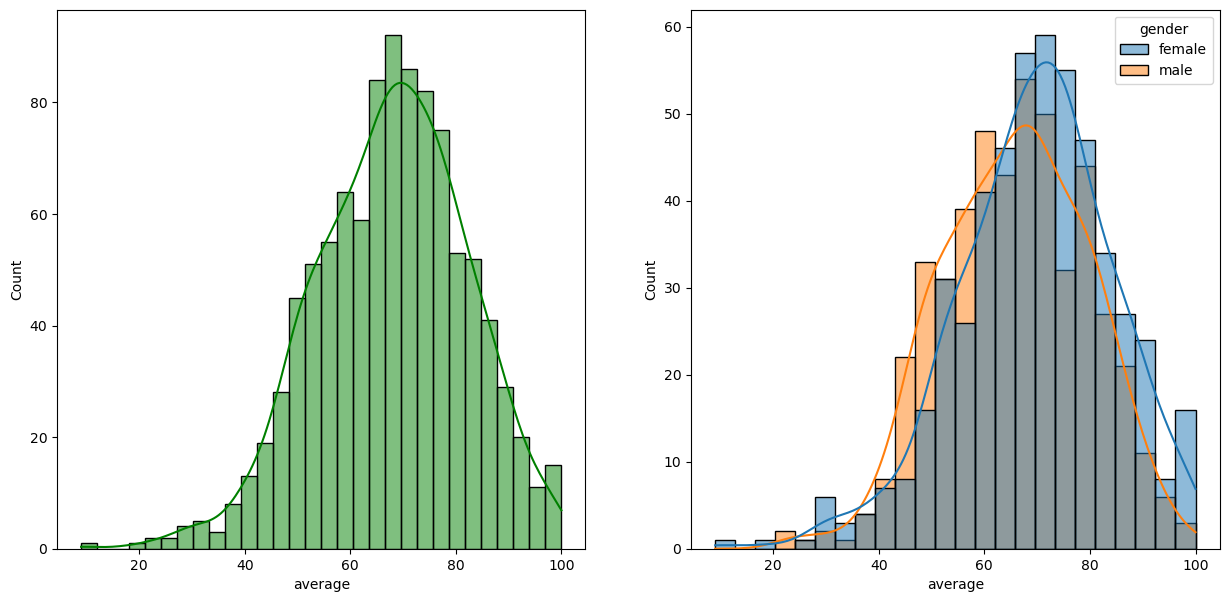

In [17]:
# Average scores by gender
fig, axs = plt.subplots(1, 2, figsize=(15, 7))
plt.subplot(121)
sns.histplot(data=df,x='average',bins=30,kde=True,color='g')
plt.subplot(122)
sns.histplot(data=df,x='average',kde=True,hue='gender')
plt.show()

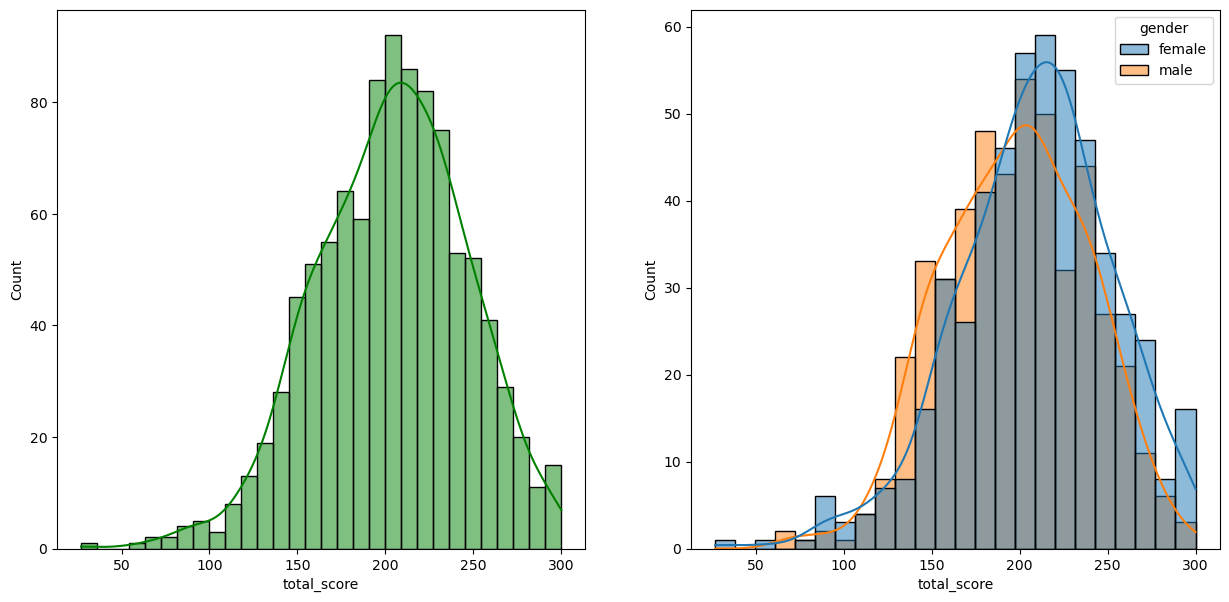

In [18]:
# total scores by gender
fig, axs = plt.subplots(1, 2, figsize=(15, 7))
plt.subplot(121)
sns.histplot(data=df,x='total_score',bins=30,kde=True,color='g')
plt.subplot(122)
sns.histplot(data=df,x='total_score',kde=True,hue='gender')
plt.show()

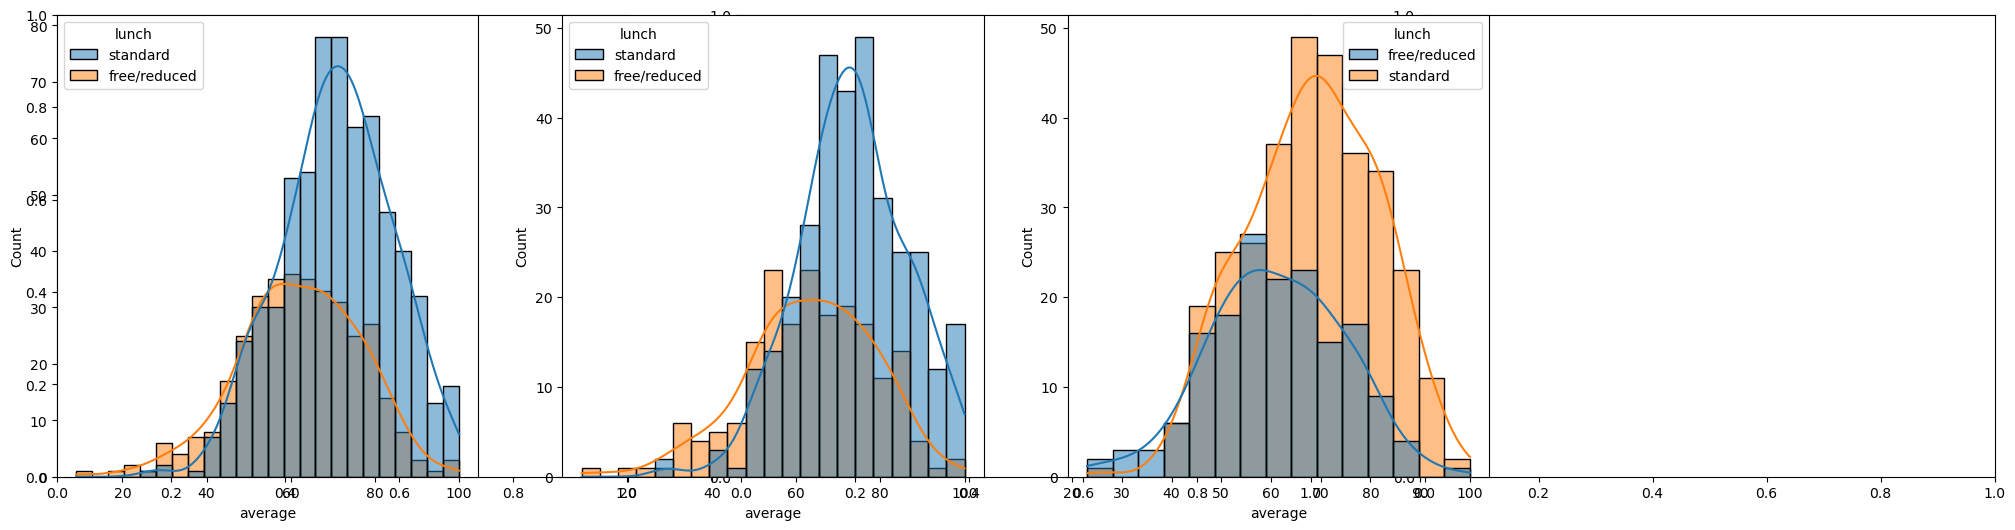

In [19]:
plt.subplots(1,3,figsize=(25,6))
plt.subplot(141)
sns.histplot(data=df,x='average',kde=True,hue='lunch')
plt.subplot(142)
sns.histplot(data=df[df.gender=='female'],x='average',kde=True,hue='lunch')
plt.subplot(143)
sns.histplot(data=df[df.gender=='male'],x='average',kde=True,hue='lunch')
plt.show()

Standard Lunch helps perform well in exams be it male/female 

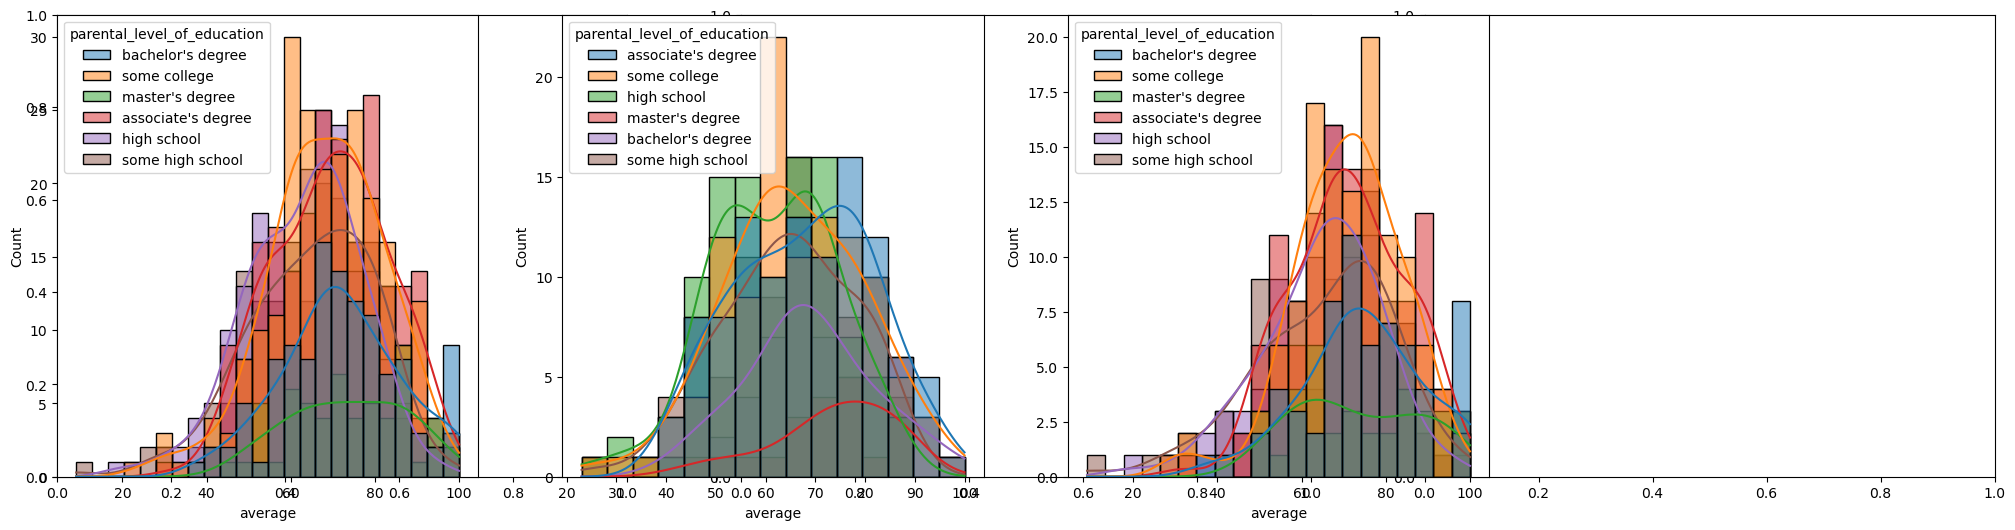

In [20]:
plt.subplots(1,3,figsize=(25,6))
plt.subplot(141)
ax =sns.histplot(data=df,x='average',kde=True,hue='parental_level_of_education')
plt.subplot(142)
ax =sns.histplot(data=df[df.gender=='male'],x='average',kde=True,hue='parental_level_of_education')
plt.subplot(143)
ax =sns.histplot(data=df[df.gender=='female'],x='average',kde=True,hue='parental_level_of_education')
plt.show()

In general parent's education don't help student perform well in exam.  
2nd plot shows that parent's whose education is of associate's degree or master's degree their male child tend to perform well in exam.  
3rd plot we can see there is no effect of parent's education on female students.

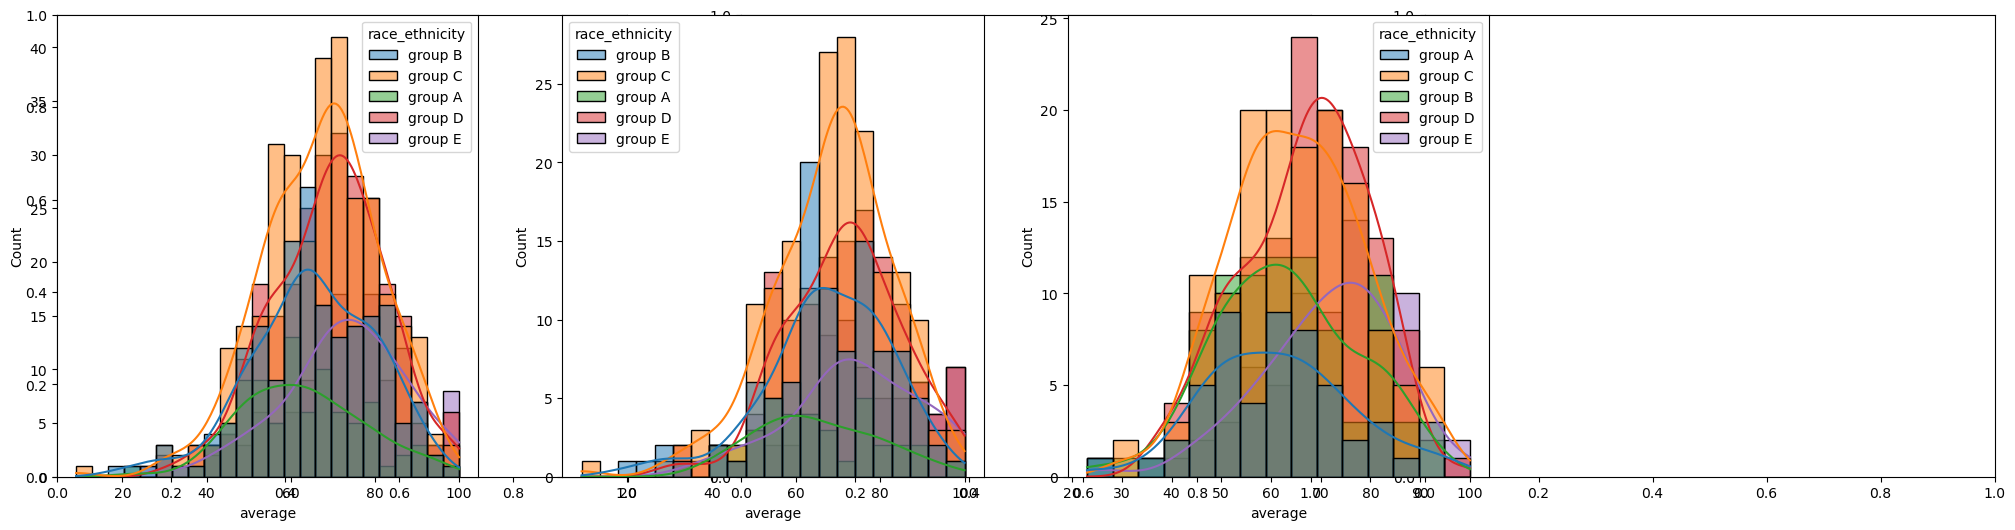

In [21]:

plt.subplots(1,3,figsize=(25,6))
plt.subplot(141)
ax =sns.histplot(data=df,x='average',kde=True,hue='race_ethnicity')
plt.subplot(142)
ax =sns.histplot(data=df[df.gender=='female'],x='average',kde=True,hue='race_ethnicity')
plt.subplot(143)
ax =sns.histplot(data=df[df.gender=='male'],x='average',kde=True,hue='race_ethnicity')
plt.show()

Students of group A and group B tends to perform poorly in exam.  
Students of group A and group B tends to perform poorly in exam irrespective of whether they are male or female

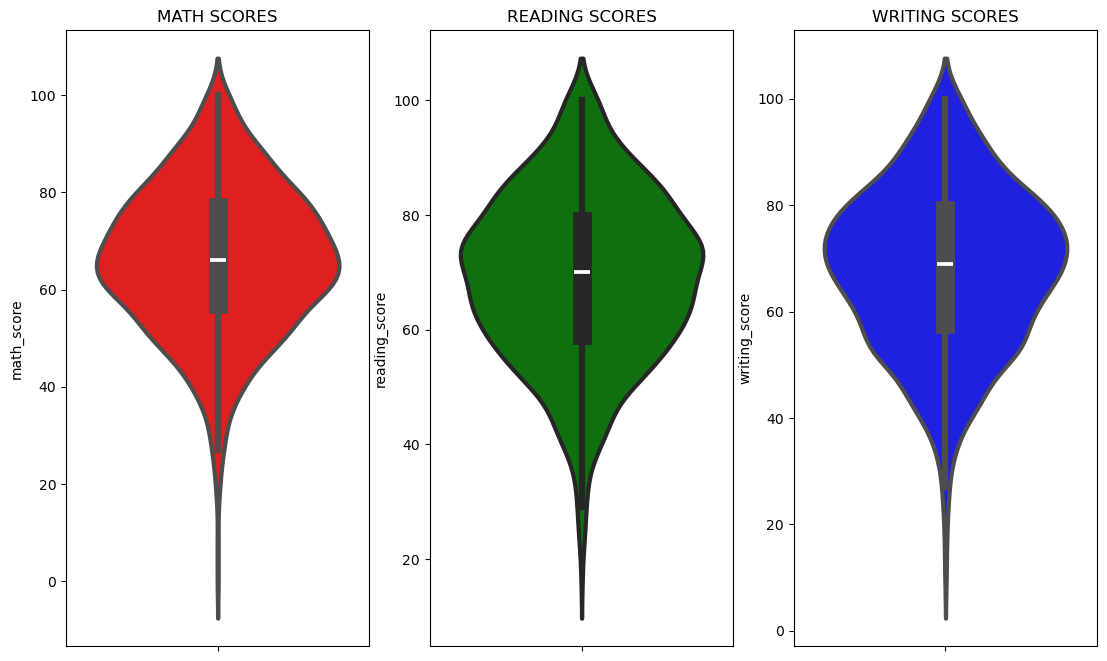

In [22]:
plt.figure(figsize=(18,8))
plt.subplot(1, 4, 1)
plt.title('MATH SCORES')
sns.violinplot(y='math_score',data=df,color='red',linewidth=3)
plt.subplot(1, 4, 2)
plt.title('READING SCORES')
sns.violinplot(y='reading_score',data=df,color='green',linewidth=3)
plt.subplot(1, 4, 3)
plt.title('WRITING SCORES')
sns.violinplot(y='writing_score',data=df,color='blue',linewidth=3)
plt.show()

From the above three plots its clearly visible that most of the students score in between 60-80 in Maths whereas in reading and writing most of them score from 50-80

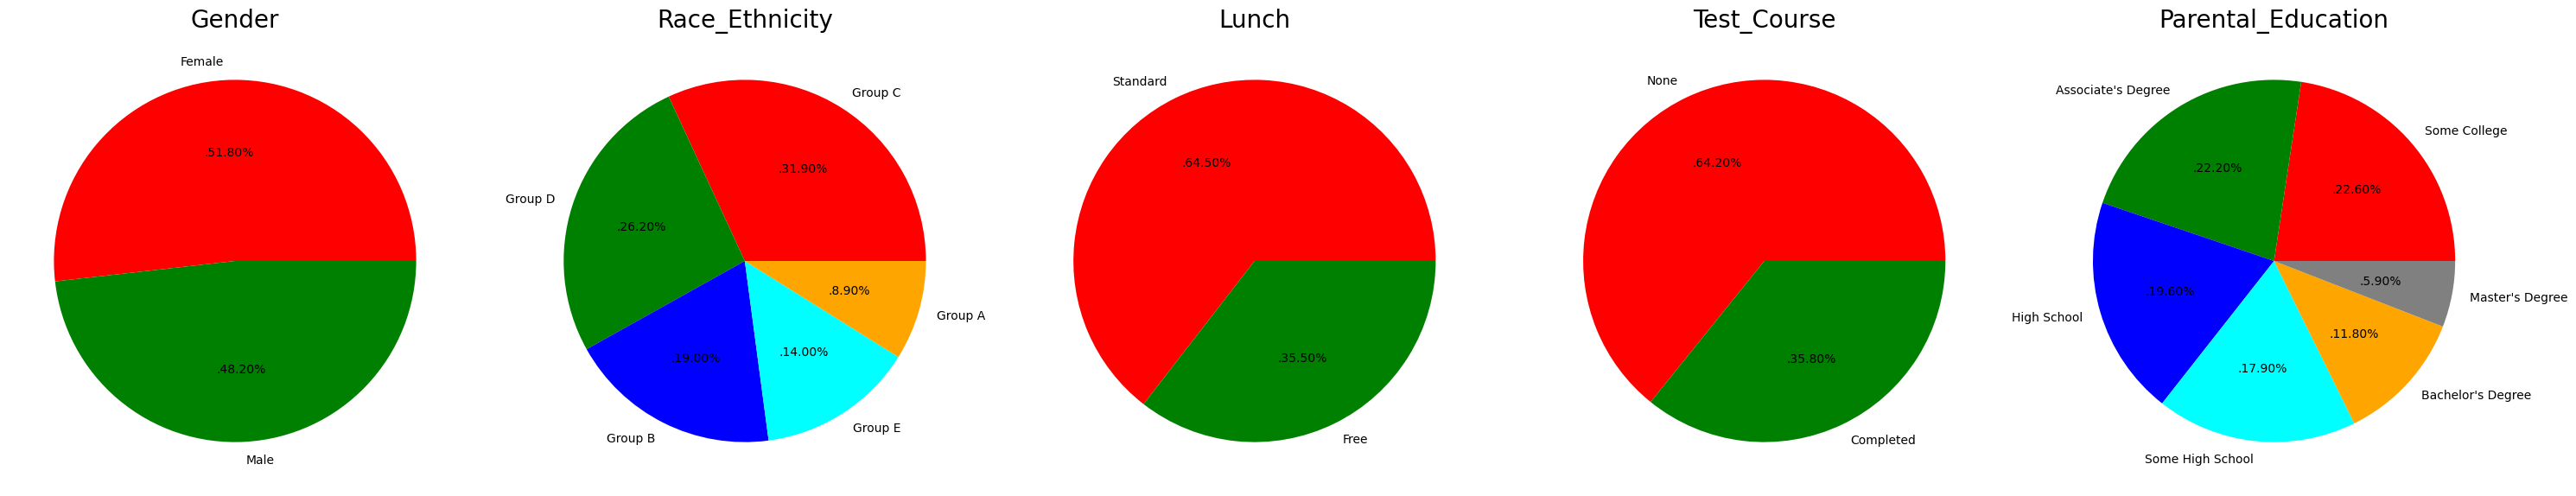

In [23]:
plt.rcParams['figure.figsize'] = (30, 12)

plt.subplot(1, 5, 1)  #1 row, 5 column, 1 chart position

size = df['gender'].value_counts()
labels = 'Female', 'Male'
color = ['red','green']

plt.pie(size, colors = color, labels = labels,autopct = '.%1.2f%%')
plt.title('Gender', fontsize = 20)
plt.axis('off')

plt.subplot(1, 5, 2)  #1 row, 5 column, 2 chart position

size = df['race_ethnicity'].value_counts()
labels = 'Group C', 'Group D','Group B','Group E','Group A'
color = ['red', 'green', 'blue', 'cyan','orange']

plt.pie(size, colors = color,labels = labels,autopct = '.%1.2f%%')
plt.title('Race_Ethnicity', fontsize = 20)
plt.axis('off')

plt.subplot(1, 5, 3)  #1 row, 5 column, 3 chart position

size = df['lunch'].value_counts()
labels = 'Standard', 'Free'
color = ['red','green']

plt.pie(size, colors = color,labels = labels,autopct = '.%1.2f%%')
plt.title('Lunch', fontsize = 20)
plt.axis('off')


plt.subplot(1, 5, 4)    #1 row, 5 column, 4 chart position

size = df['test_preparation_course'].value_counts()
labels = 'None', 'Completed'
color = ['red','green']

plt.pie(size, colors = color,labels = labels,autopct = '.%1.2f%%')
plt.title('Test_Course', fontsize = 20)
plt.axis('off')


plt.subplot(1, 5, 5)    #1 row, 5 column, 5 chart position

size = df['parental_level_of_education'].value_counts()
labels = 'Some College', "Associate's Degree",'High School','Some High School',"Bachelor's Degree","Master's Degree"
color = ['red', 'green', 'blue', 'cyan','orange','grey']

plt.pie(size, colors = color,labels = labels,autopct = '.%1.2f%%')
plt.title('Parental_Education', fontsize = 20)
plt.axis('off')


plt.tight_layout()      #Adjusts spacing between charts to reduce overlapping labels and titles.
plt.grid()

plt.show()

Number of Male and Female students is almost equal  
Number students are greatest in Group C  
Number of students who have standard lunch are greater  
Number of students who have not enrolled in any test preparation course is greater  
Number of students whose parental education is "Some College" is greater followed closely by "Associate's Degree"

### 5] Fetaure wise visulization (Univariate/Bivariate analysis)

GENDER COLUMN  
- How is distribution of Gender ?  
- Does gender has any impact on student's performance ?

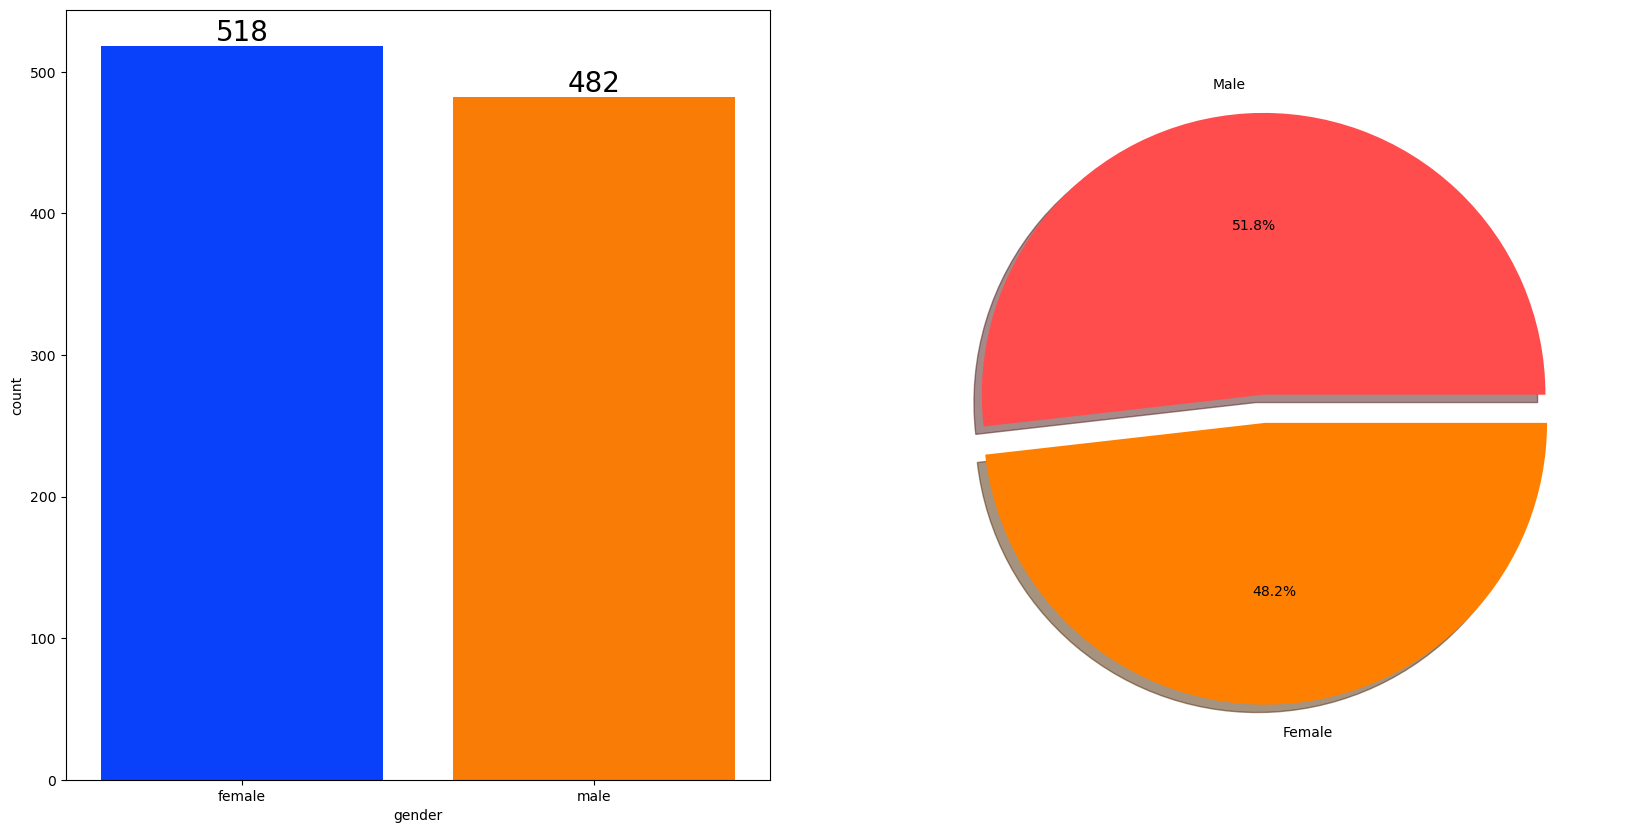

In [24]:
#univariate analysis for distribution of gender
f,ax=plt.subplots(1,2,figsize=(20,10))
sns.countplot(x=df['gender'],data=df,palette ='bright',ax=ax[0],saturation=0.95)
for container in ax[0].containers:
    ax[0].bar_label(container,color='black',size=20)
    
plt.pie(x=df['gender'].value_counts(),labels=['Male','Female'],explode=[0,0.1],autopct='%1.1f%%',shadow=True,colors=['#ff4d4d','#ff8000'])
plt.show()

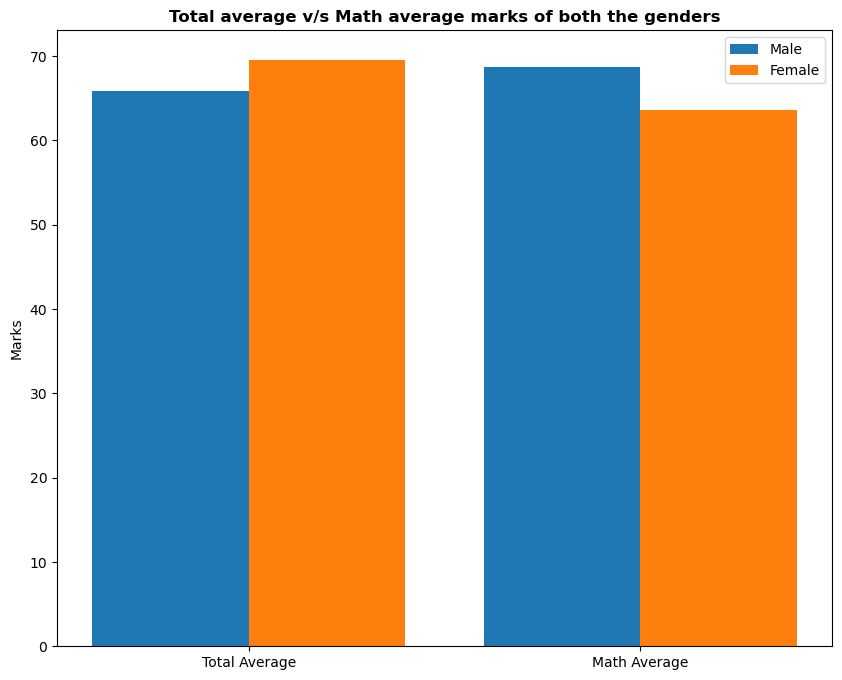

In [25]:
#bivariate analysis for checking if gender has any impact on student performance

gender_group = df.groupby('gender').mean(numeric_only = True)
gender_group

plt.figure(figsize=(10, 8))

X = ['Total Average','Math Average']

female_scores = [gender_group['average'][0], gender_group['math_score'][0]]
male_scores = [gender_group['average'][1], gender_group['math_score'][1]]

X_axis = np.arange(len(X))
  
plt.bar(X_axis - 0.2, male_scores, 0.4, label = 'Male')
plt.bar(X_axis + 0.2, female_scores, 0.4, label = 'Female')
  
plt.xticks(X_axis, X)
plt.ylabel("Marks")
plt.title("Total average v/s Math average marks of both the genders", fontweight='bold')
plt.legend()
plt.show()

On an average females have a better overall score than men  
whereas males have scored higher in maths

Race/Ethnicity Column
- How is the distribution of race/ethnicity
- does the column have any impact on student's performance?

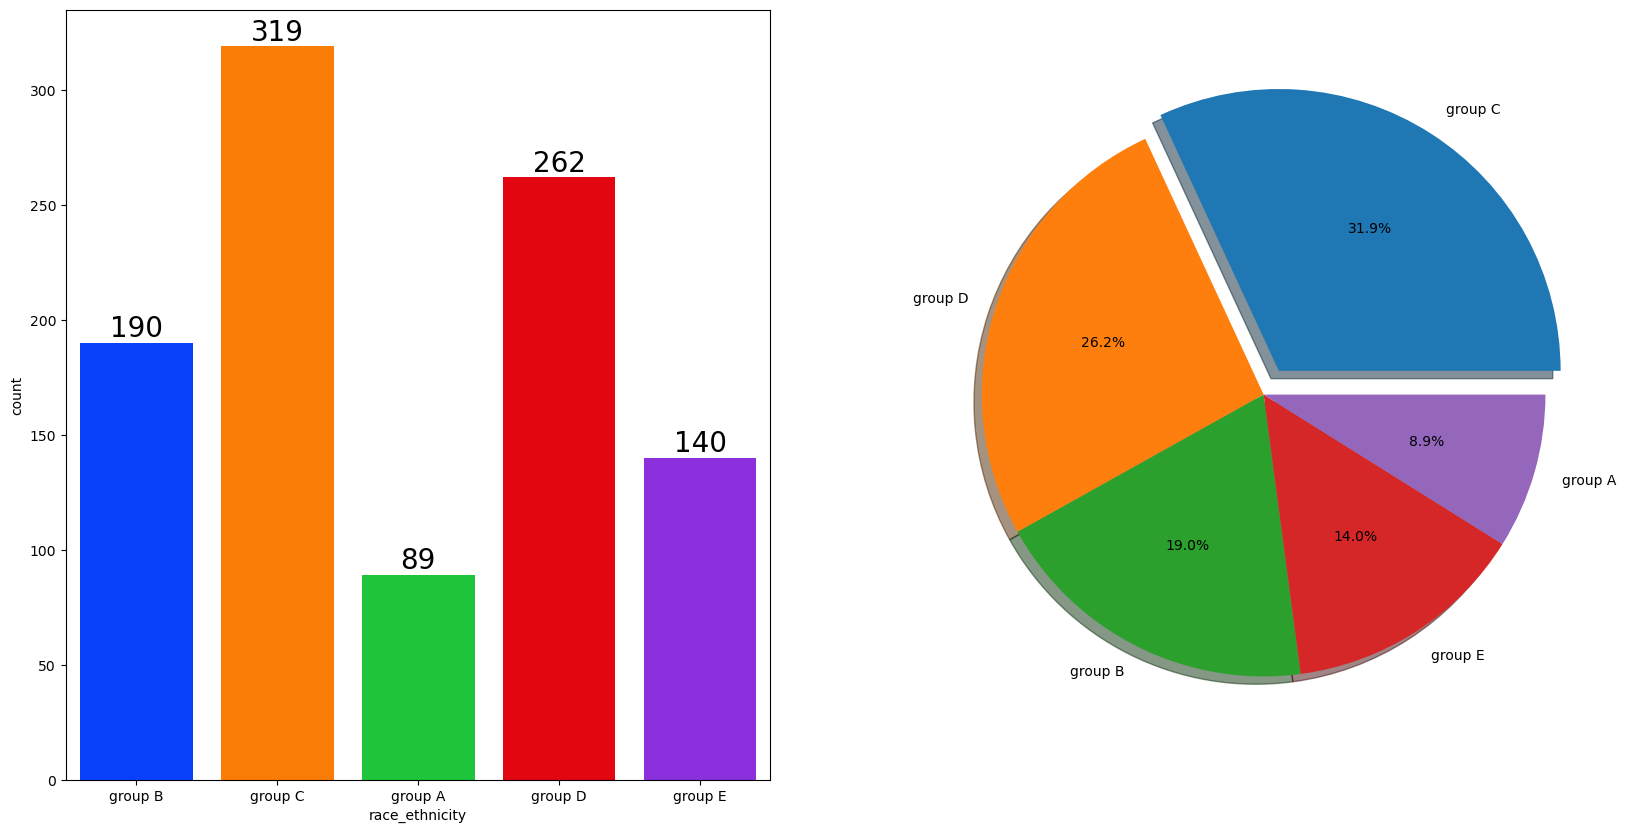

In [38]:
# univariate analysis for distribution of race/ethnicity
f,ax=plt.subplots(1,2,figsize=(20,10))
sns.countplot(x=df['race_ethnicity'],data=df,palette = 'bright',ax=ax[0],saturation=0.95)
for container in ax[0].containers:
    ax[0].bar_label(container,color='black',size=20)
    
plt.pie(x = df['race_ethnicity'].value_counts(),labels=df['race_ethnicity'].value_counts().index,explode=[0.1,0,0,0,0],autopct='%1.1f%%',shadow=True)
plt.show() 

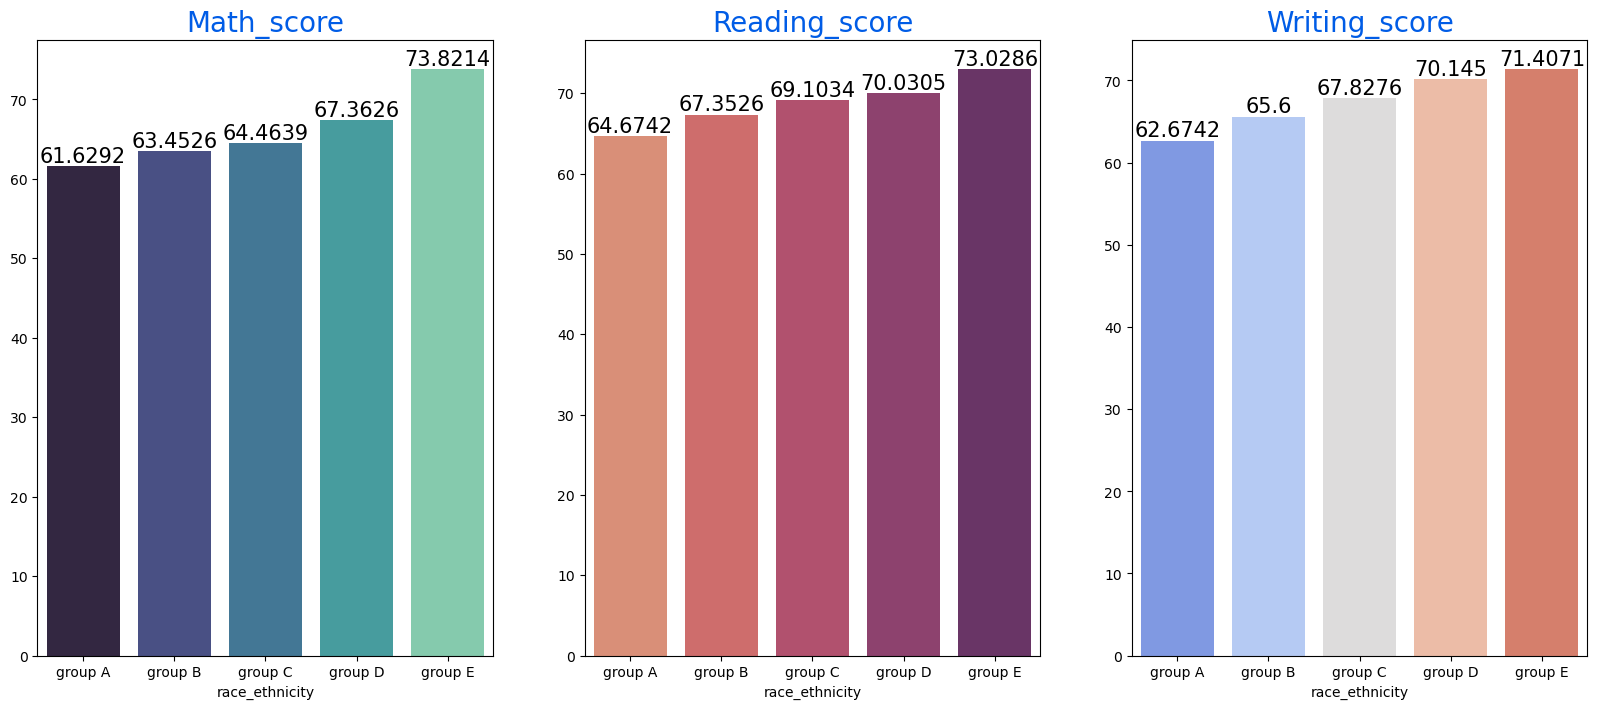

In [37]:
# bivariate analysis for checking if Race/Ethnicity has any impact on student performance
Group_data2=df.groupby('race_ethnicity')
f,ax=plt.subplots(1,3,figsize=(20,8))
sns.barplot(x=Group_data2['math_score'].mean().index,y=Group_data2['math_score'].mean().values,palette = 'mako',ax=ax[0])
ax[0].set_title('Math_score',color='#005ce6',size=20)

for container in ax[0].containers:
    ax[0].bar_label(container,color='black',size=15)

sns.barplot(x=Group_data2['reading_score'].mean().index,y=Group_data2['reading_score'].mean().values,palette = 'flare',ax=ax[1])
ax[1].set_title('Reading_score',color='#005ce6',size=20)

for container in ax[1].containers:
    ax[1].bar_label(container,color='black',size=15)

sns.barplot(x=Group_data2['writing_score'].mean().index,y=Group_data2['writing_score'].mean().values,palette = 'coolwarm',ax=ax[2])
ax[2].set_title('Writing_score',color='#005ce6',size=20)

for container in ax[2].containers:
    ax[2].bar_label(container,color='black',size=15)
plt.show()

Group E students have scored the highest marks.  
Group A students have scored the lowest marks.  
Students from a lower Socioeconomic status have a lower avg in all course subjects

Parental Level of Education column  
- Educational Background of parent   
- does it has any impact on student's performance

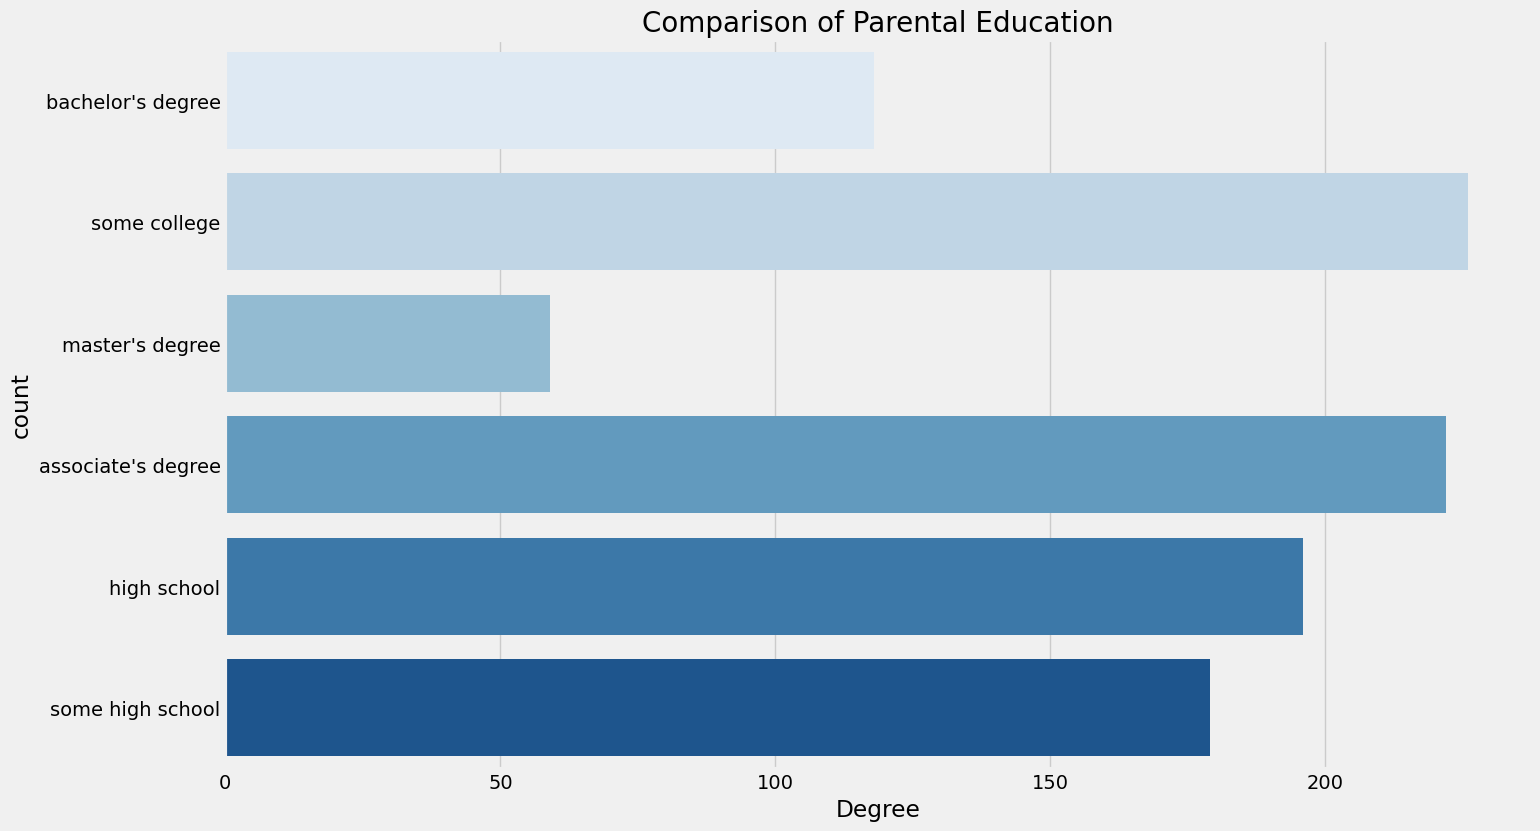

In [40]:
# univariate analysis for distribution of educational background of parents
plt.rcParams['figure.figsize'] = (15, 9)
plt.style.use('fivethirtyeight')
sns.countplot(df['parental_level_of_education'], palette = 'Blues')
plt.title('Comparison of Parental Education', fontweight = 30, fontsize = 20)
plt.xlabel('Degree')
plt.ylabel('count')
plt.show()

Largest number of parents are from some college.

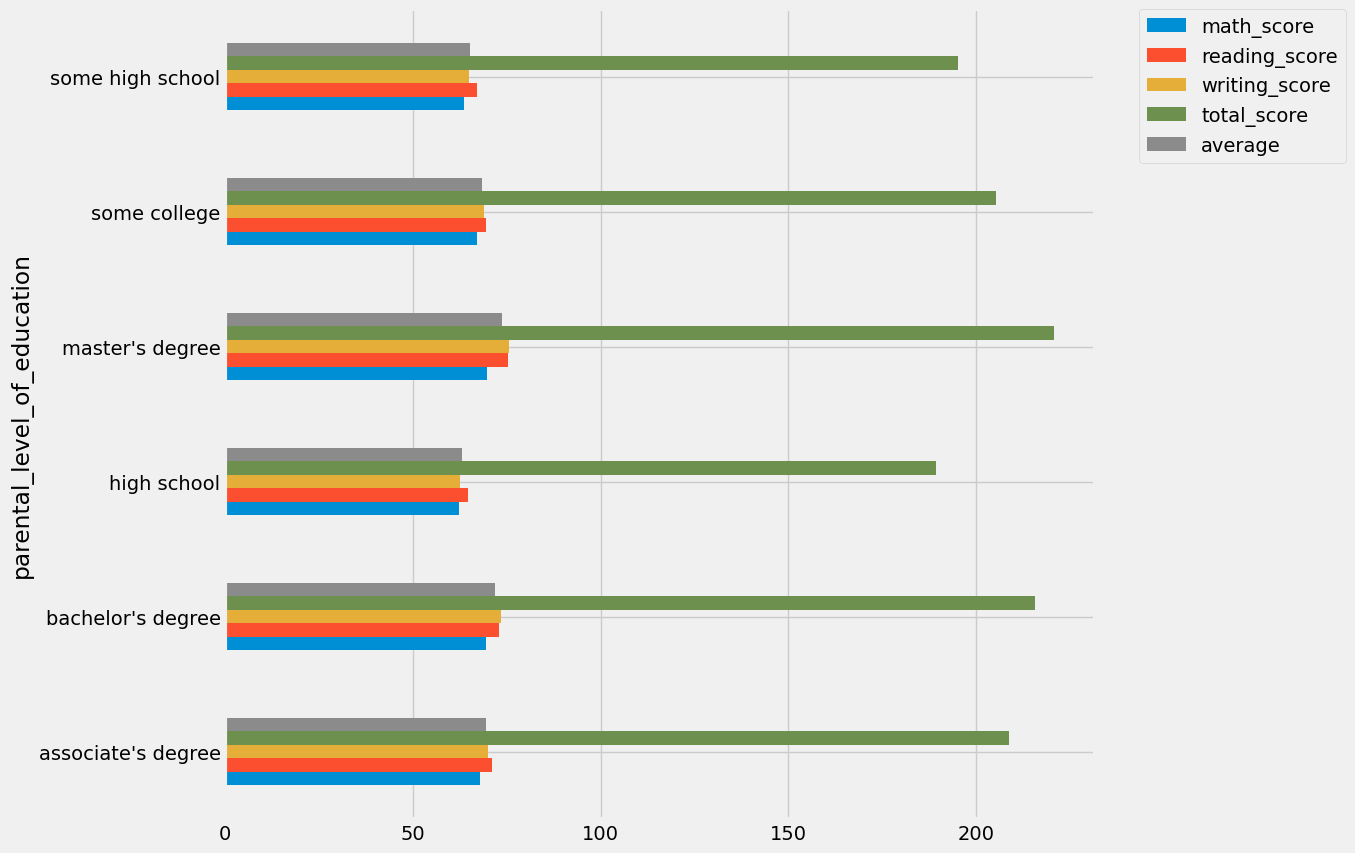

In [ ]:
# bivariate analysis for checking if parental_education has any impact on student performance
df.groupby('parental_level_of_education').mean(numeric_only=True).plot(kind='barh', figsize=(10, 10))
plt.legend(bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)
plt.show()

The score of student whose parents possess master and bachelor level education are higher than others.

Lunch Column
- Which type of lunch is common among students?
- what is effect of lunch on test performance?

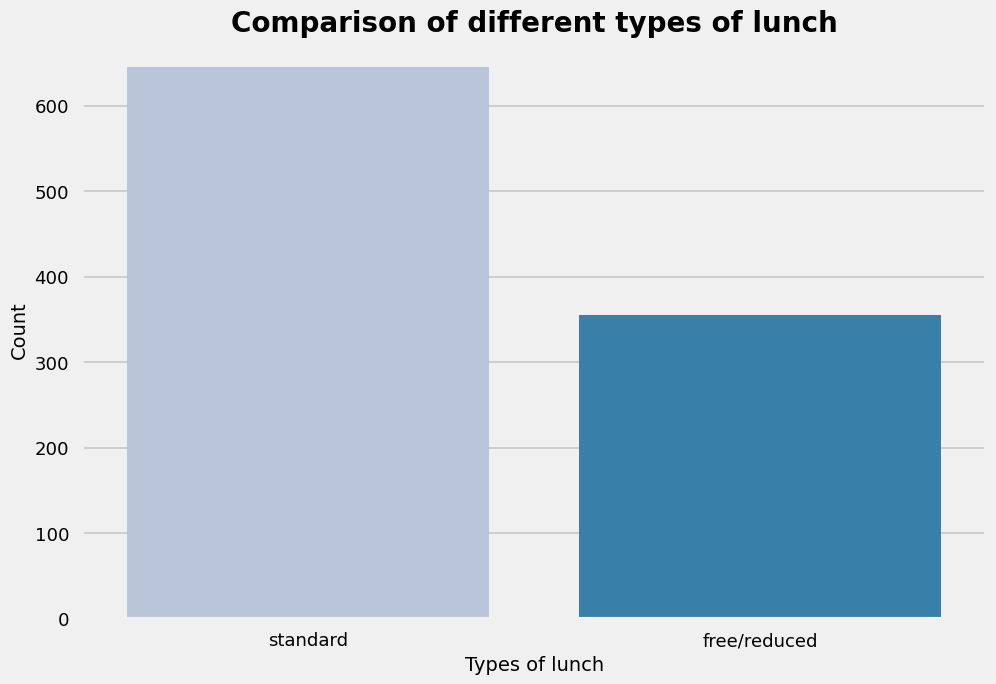

In [47]:
# univariate analysis for checking which is most common lunch type among students
plt.rcParams['figure.figsize'] = (15, 9)
plt.rcParams['figure.figsize'] = (15, 9)
plt.style.use('seaborn-v0_8-talk') 
sns.countplot(data=df, x='lunch', hue='lunch', palette='PuBu', legend=False)
plt.title('Comparison of different types of lunch', fontweight='bold', fontsize=20)
plt.xlabel('Types of lunch', fontsize=14)
plt.ylabel('Count', fontsize=14)

plt.show()

Students being served Standard lunch was more than free lunch

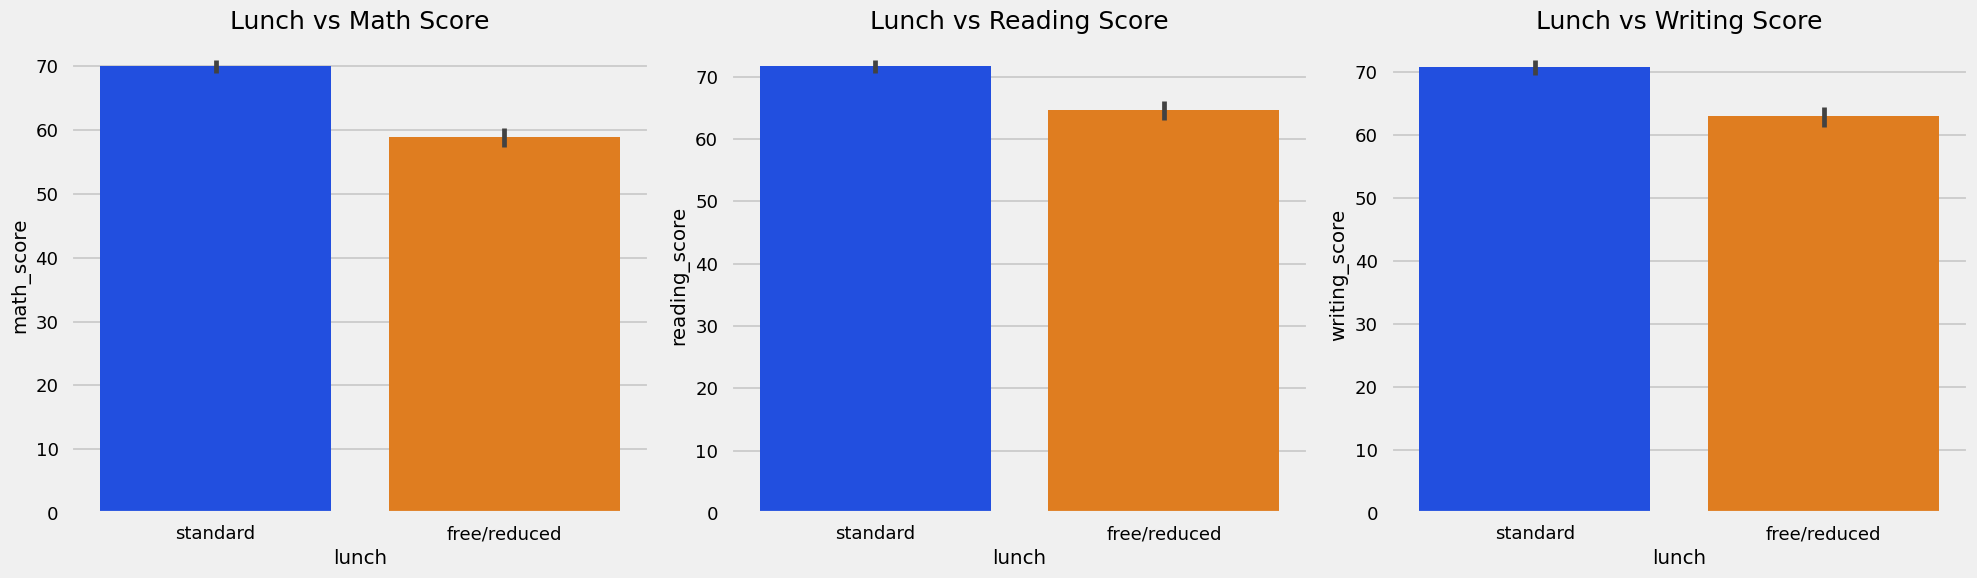

In [60]:
# bivariate analysis for checking if lunch type intake has any impact on students performance
f, ax = plt.subplots(1, 3, figsize=(20, 6))

# Comparing lunch type against all three exam scores
sns.barplot(x='lunch', y='math_score', data=df, palette='bright', ax=ax[0])
ax[0].set_title('Lunch vs Math Score', size=18)

sns.barplot(x='lunch', y='reading_score', data=df, palette='bright', ax=ax[1])
ax[1].set_title('Lunch vs Reading Score', size=18)

sns.barplot(x='lunch', y='writing_score', data=df, palette='bright', ax=ax[2])
ax[2].set_title('Lunch vs Writing Score', size=18)

plt.tight_layout()
plt.show()

Students who get Standard Lunch tend to perform better than students who got free/reduced lunch

TEST PREPARATION COURSE COLUMN
- Distribution of no of students who have completed / not completed test prep?
- Does Test prepration course has any impact on student's performance ?

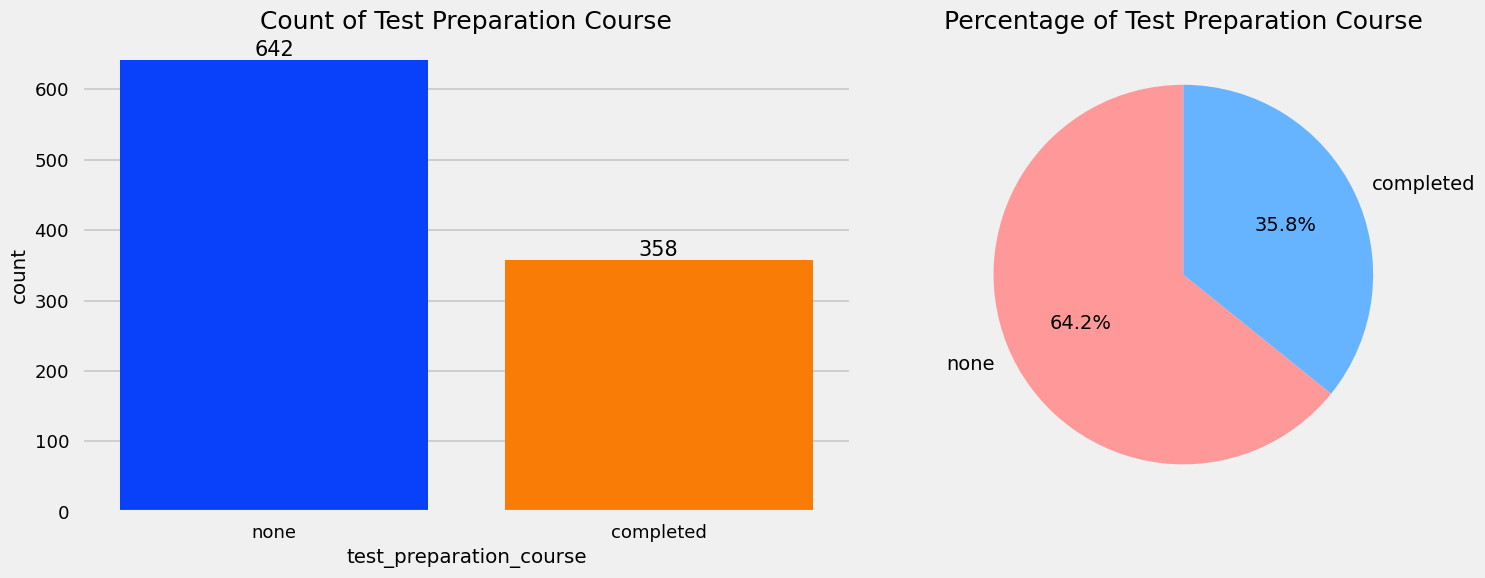

In [67]:
# Univariate analysis for checking o of students who have completed / not completed test prep?
f, ax = plt.subplots(1, 2, figsize=(16, 6))

# Countplot for exact numbers
sns.countplot(x='test_preparation_course', data=df, palette='bright', saturation=0.95, ax=ax[0])
ax[0].set_title('Count of Test Preparation Course', size=18)
for container in ax[0].containers:
    ax[0].bar_label(container, color='black', size=15)

df['test_preparation_course'].value_counts().plot.pie(
    autopct='%1.1f%%', 
    ax=ax[1], 
    colors=['#ff9999', '#66b3ff'], 
    startangle=90, 
    textprops={'fontsize': 14}
)
ax[1].set_title('Percentage of Test Preparation Course', size=18)
ax[1].set_ylabel('') # Hides the y-label for cleaner look

plt.tight_layout()
plt.show()

The number of students who did not complete the test preparation course are more than the students who completed it!

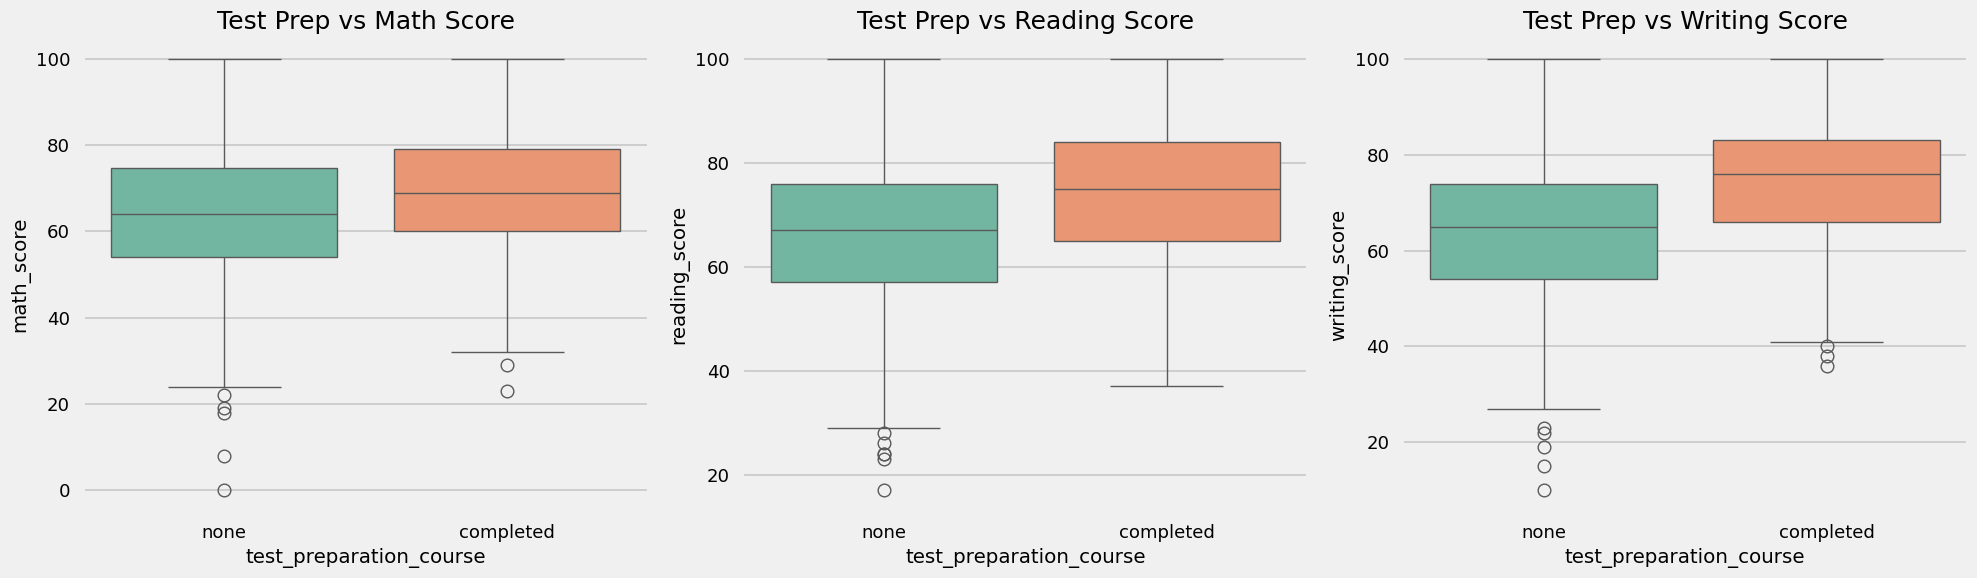

                         math_score  reading_score  writing_score
test_preparation_course                                          
completed                 69.695531      73.893855      74.418994
none                      64.077882      66.534268      64.504673


In [ ]:
#bivariate analysis for checking if Test prepration course has any impact on student's performance?
f, ax = plt.subplots(1, 3, figsize=(20, 6))

# Math Score
sns.boxplot(x='test_preparation_course', y='math_score', data=df, palette='Set2', ax=ax[0])
ax[0].set_title('Test Prep vs Math Score', size=18)

# Reading Score
sns.boxplot(x='test_preparation_course', y='reading_score', data=df, palette='Set2', ax=ax[1])
ax[1].set_title('Test Prep vs Reading Score', size=18)

# Writing Score
sns.boxplot(x='test_preparation_course', y='writing_score', data=df, palette='Set2', ax=ax[2])
ax[2].set_title('Test Prep vs Writing Score', size=18)

plt.tight_layout()
plt.show()

# Print exact average scores
print(df.groupby('test_preparation_course')[['math_score', 'reading_score', 'writing_score']].mean())

Students who have completed the Test Prepration Course have scores higher in all three categories than those who haven't taken the course

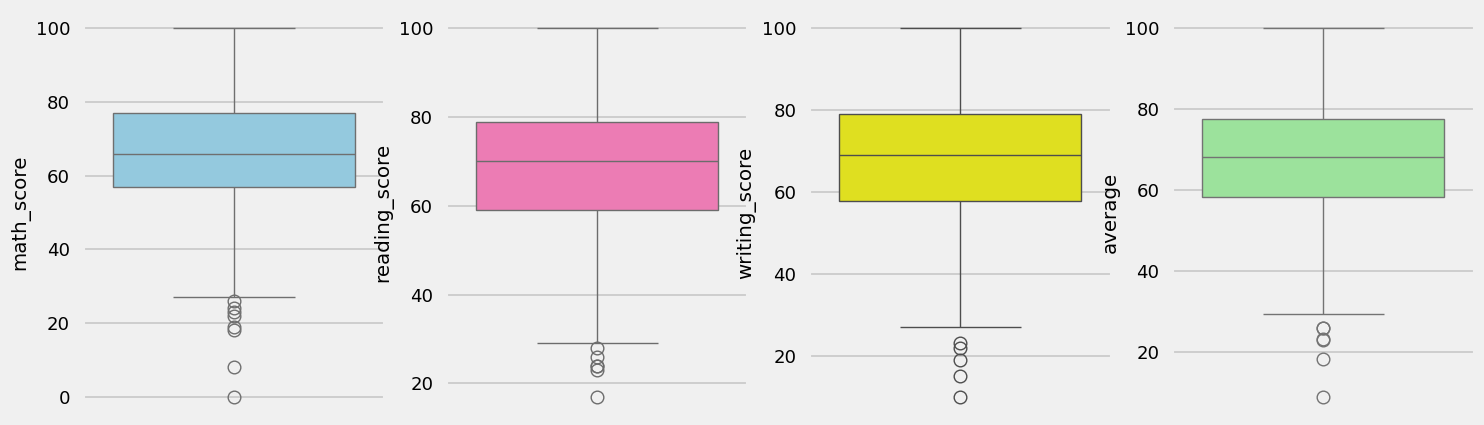

In [66]:
# checking outliers in the data
plt.subplots(1,4,figsize=(16,5))
plt.subplot(141)
sns.boxplot(df['math_score'],color='skyblue')
plt.subplot(142)
sns.boxplot(df['reading_score'],color='hotpink')
plt.subplot(143)
sns.boxplot(df['writing_score'],color='yellow')
plt.subplot(144)
sns.boxplot(df['average'],color='lightgreen')
plt.show()

Multivariate Analysis

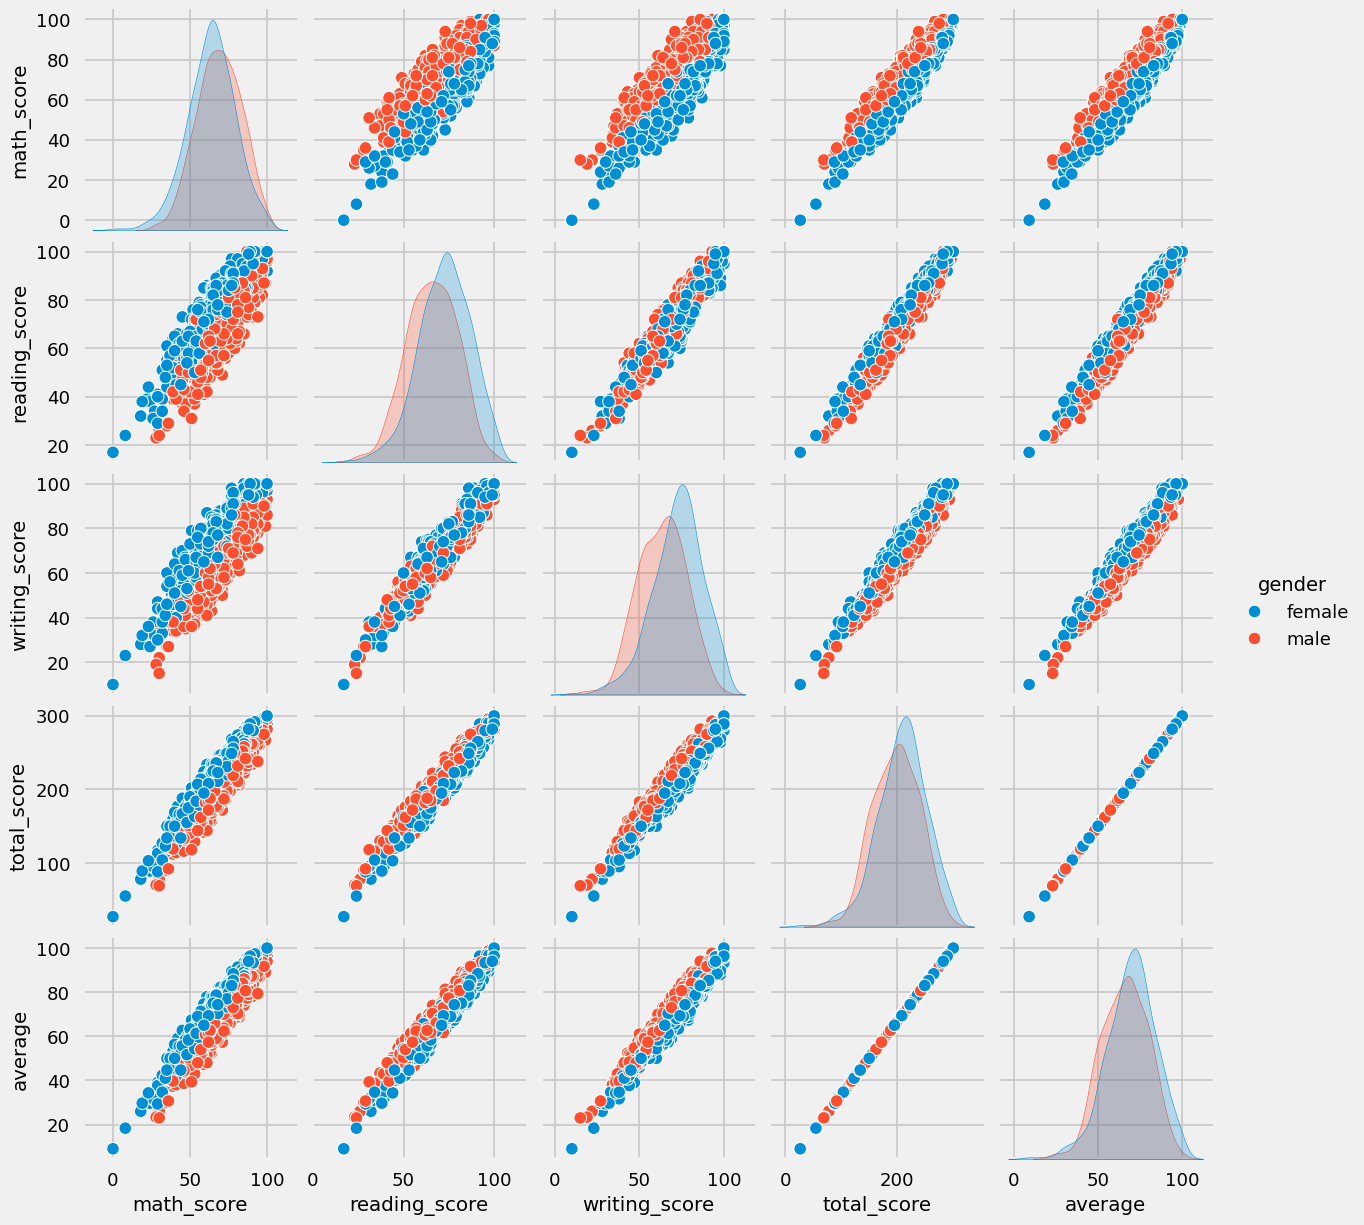

In [ ]:
sns.pairplot(df,hue = 'gender')
plt.show()

From the above plot it is clear that all the scores increase linearly with each other.

Conclusion of the analysis
- Student's Performance is related with lunch, race, parental level education
- Females lead in pass percentage and also are top-scorers
- Student's Performance is not much related with test preparation course because the student's who took test_prep_course will generally perform better then who didn't.
- Finishing preparation course is benefitial.